# UCE Airfoil Self-Noise

## Imports

In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## a) Load and inspect data

In [2]:
base_dir = os.getcwd()
data_filepath = os.path.join(base_dir, "airfoil_self_noise.dat")

data = pd.read_csv(
    data_filepath,
    sep=r"\s+",
    header=None,
    names=[
        "Frequency", "Angle of attack", "Chord length",
        "Free-stream velocity", "Suction-side displacement thickness",
        "Sound pressure level"])

display(data.head())

# Check data types and missing values
display(data.dtypes)
display(data.isna().sum())

,Frequency,Angle of attack,Chord length,Free-stream velocity,Suction-side displacement thickness,Sound pressure level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


Frequency                                int64
Angle of attack                        float64
Chord length                           float64
Free-stream velocity                   float64
Suction-side displacement thickness    float64
Sound pressure level                   float64
dtype: object

Frequency                              0
Angle of attack                        0
Chord length                           0
Free-stream velocity                   0
Suction-side displacement thickness    0
Sound pressure level                   0
dtype: int64

### Frequency vs sound pressure scatterplot

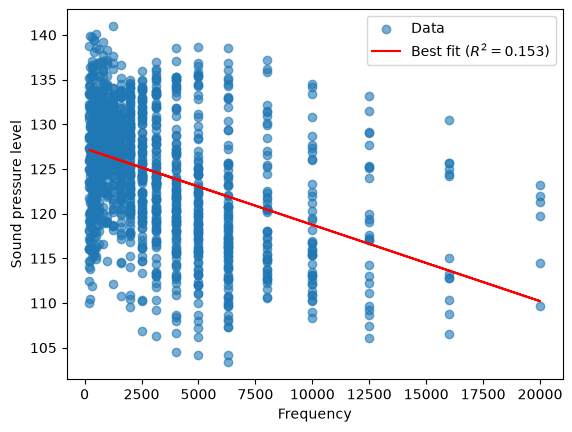

In [4]:
x = data["Frequency"]
y = data["Sound pressure level"]
fit = linregress(x, y)

plt.scatter(x, y, alpha=0.6, label="Data")
plt.plot(x, fit.intercept + fit.slope * x, color="red",
         label=f"Best fit ($R^2={fit.rvalue**2:.3f}$)")
plt.xlabel("Frequency")
plt.ylabel("Sound pressure level")
plt.legend()
plt.show()

Sound pressure generally decreases decreases as frequency increases, but the relationship is curved and has a high amount of scatter. Most data is clustered abround lowe frequencies, and only certail discrete frequencies contain data. Each frequency has a wide range of sound pressure levels. A straight line shows the overall downward trend, but does not represent the pattern well. The $R^2$ value of 0.153 shows that the line of best fit does not fit the data well.

## b) Univariate regressor

### Split data

In [6]:
X = data.drop(columns="Sound pressure level")
y = data["Sound pressure level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

### Fit linear regression with frequency as predictor

Intercept: 127.401
Slope: -0.000879
R² (training): 0.168


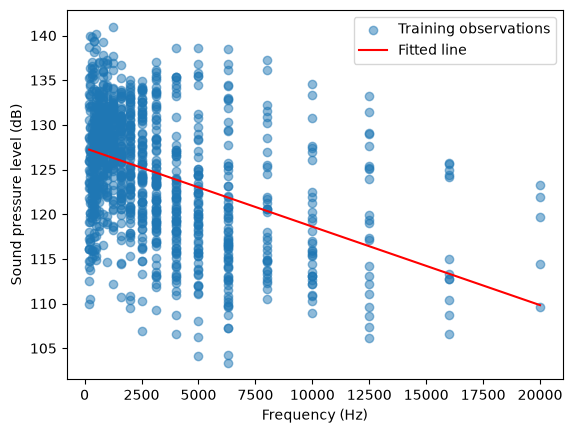

In [9]:
X_freq = X_train[["Frequency"]]
model = LinearRegression().fit(X_freq, y_train)

print(f"Intercept: {model.intercept_:.3f}")
print(f"Slope: {model.coef_[0]:.6f}")
print(f"R² (training): {model.score(X_freq, y_train):.3f}")

# Plot training observations and fitted line
plt.scatter(X_freq["Frequency"], y_train, alpha=0.5, label="Training observations")
x_line = X_freq.sort_values("Frequency")
plt.plot(x_line["Frequency"], model.predict(x_line), color="red", label="Fitted line")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Sound pressure level (dB)")
plt.legend()
plt.show()

For each 1 Hz increase in frequency, the model predicts a -0.000879 dB change in sound pressure level.

## c) Multiple Linear Regression

In [ ]:
# Fit both models on the same training data
frequency_model = LinearRegression().fit(X_train[["Frequency"]], y_train)
multiple_model = LinearRegression().fit(X_train, y_train)

def metrics(model, X, y):
    predictions = model.predict(X)
    return {
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions)}

results = pd.DataFrame({
    ("Training", "Frequency only"): metrics(frequency_model, X_train[["Frequency"]], y_train),
    ("Test", "Frequency only"): metrics(frequency_model, X_test[["Frequency"]], y_test),
    ("Training", "All predictors"): metrics(multiple_model, X_train, y_train),
    ("Test", "All predictors"): metrics(multiple_model, X_test, y_test),
}).T

display(results)

,,RMSE,R²
Training,Frequency only,6.248496,0.167789
Test,Frequency only,6.734021,0.094844
Training,All predictors,4.826601,0.503448
Test,All predictors,4.704109,0.558298


The model using all five predictors performs better on the test set. RMSE drops from about 6.73 to 4.70, and $R^2$ rises from 0.095 to 0.558. This suggests additional predictors improve performance. Training and testing performance appear similar.

## d) Plot multiple regression results

### Test residuals versus predicted values

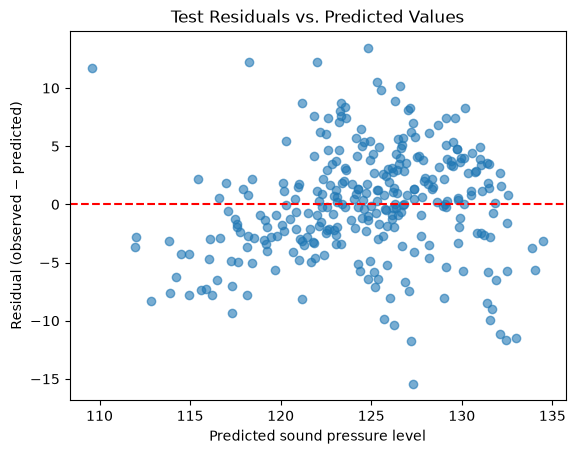

In [14]:
y_pred = multiple_model.predict(X_test)
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted sound pressure level")
plt.ylabel("Residual (observed − predicted)")
plt.title("Test Residuals vs. Predicted Values")
plt.show()

The residuals are generally centered around zero, indicating that the model does not have a strong overall bias. The plot shows random scatter, with similar variance at dofferent sound pressure levels. There does seem to be slightly more spread underneath the zero line, suggesting the model may sometimes overpredict sound pressure levels, since negative residuals mean predicted values exceed observed values. However, this trend is subtle, and there is not enough evidence to conclude systematic bias.